In [ ]:
!pip install implicit pandas scipy scikit-learn -qqq
!pip install git+https://github.com/daviddavo/lightfm -qqq
#!kaggle datasets download -d zygmuntz/goodbooks-10k -qqq
#!unzip -o goodbooks-10k.zip
!pip install rarfile -qqq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 43.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import gdown, zipfile, rarfile, os, shutil


url = 'https://drive.google.com/file/d/1sTqYA-zDWwEhla_ahUeznWJGICTx7T0n/view?usp=sharing'
rar_path = gdown.download(url, quiet=False, fuzzy=True)

# Extract RAR and automatically extract nested ZIPs
with rarfile.RarFile(rar_path) as r:
    for file in r.namelist():
        if file.endswith('.zip'):
            with zipfile.ZipFile(r.open(file)) as z:
                z.extractall('')
        else:
            r.extract(file, '')



Downloading...
From: https://drive.google.com/uc?id=1sTqYA-zDWwEhla_ahUeznWJGICTx7T0n
To: /content/books.rar
100%|██████████| 12.1M/12.1M [00:00<00:00, 94.4MB/s]


In [ ]:
import pandas as pd
import numpy as np
import random
from scipy.sparse import csr_matrix, csc_matrix
from lightfm import LightFM
from lightfm.data import Dataset
from lightfm.evaluation import precision_at_k as calculate_lightfm_precision_at_k
from lightfm.evaluation import recall_at_k as calculate_lightfm_recall_at_k
from lightfm.evaluation import auc_score as calculate_lightfm_auc_score
from sklearn.model_selection import train_test_split
from IPython.display import display
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt;
import time, datetime

#1. Установка библиотек
Установите библиотеку LightFM и дополнительные зависимости для
работы с данными (pandas, scipy). LightFM позволяет строить гибридные
рекомендательные системы, объединяющие коллаборативную фильтрацию и
контентные признаки
#2. Импорт необходимых библиотек
Импортируйте LightFM, класс Dataset из lightfm.data для построения
матриц взаимодействий из сырых данных, функции оценки precision_at_k,
recall_at_k и auc_score из lightfm.evaluation, а также pandas для работы с CSVфайлами
#3. Загрузка датасета Goodbooks 10k Updated с Kaggle

Загрузите три основных CSV-файла:

‒ ratings.csv — оценки пользователей (user_id, book_id, rating)

‒ books.csv — метаданные книг (book_id, authors
original_publication_year, average_rating)

‒ to_read.csv — список «хочу прочитать» (user_id, book_id) — это  неявный

фидбек, который можно использовать как дополнительный источник взаимодействий

In [ ]:
print("Задания 1-3: Окружение настроено, библиотеки импортированы.")

user_ratings_dataframe = pd.read_csv('ratings.csv')
book_metadata_dataframe = pd.read_csv('books.csv')
user_to_read_dataframe = pd.read_csv('to_read.csv')

print(f"Загружено оценок: {len(user_ratings_dataframe)}")
print(f"Загружено книг: {len(book_metadata_dataframe)}")

Задания 1-3: Окружение настроено, библиотеки импортированы.
Загружено оценок: 981756
Загружено книг: 10000


#4. Подготовка данных с использованием класса Dataset LightFM

В отличие от встроенной функции fetch_movielens, для Goodbooks требуется ручное построение матриц.
Класс Dataset решает эту задачу.

‒ Создайте экземпляр класса Dataset

‒ Выполните fit для всех пользователей и книг, передав итераторы с user_id и book_id

‒ Постройте матрицу взаимодействий (interactions) с помощью build_interactions — передайте пары
(user_id, book_id) для каждой оценки. LightFM автоматически сопоставит исходные идентификаторы с

внутренними числовыми индексами

‒ При необходимости можно использовать веса (например, значение рейтинга от 1 до 5) вместо бинарных взаимодействий
#5. Построение матрицы признаков книг (item_features)

Ключевое преимущество гибридной системы — использование контентных признаков:

‒ Из файла books.csv извлеките признаки: автора (authors), год публикации (original_publication_year)

‒ Для каждого book_id создайте список соответствующих признаков (например, автор как категориальный
признак)

‒ Вызовите build_item_features для построения разреженной матрицы признаков размером [количество
книг × количество уникальных признаков]

‒ Если у вас есть пользовательские признаки (например, возраст или любимые жанры), их можно добавить
аналогично через build_user_features


In [ ]:
print("Задание 4-5: Подготовка данных и признаков с помощью класса Dataset")

training_ratings_dataframe, testing_ratings_dataframe = train_test_split(
    user_ratings_dataframe,
    test_size=0.2,
    random_state=42
)

all_users_union_array = np.union1d(user_ratings_dataframe['user_id'].unique(), user_to_read_dataframe['user_id'].unique());

all_items_union_array = np.union1d(user_ratings_dataframe['book_id'].unique(), book_metadata_dataframe['book_id'].unique());
all_items_union_array = np.union1d(all_items_union_array, user_to_read_dataframe['book_id'].unique());

lightfm_dataset_manager = Dataset();

lightfm_dataset_manager.fit(
    users=all_users_union_array,
    items=all_items_union_array
);

book_metadata_dataframe['authors'] = book_metadata_dataframe['authors'].fillna('Unknown');
book_metadata_dataframe['original_publication_year'] = book_metadata_dataframe['original_publication_year'].fillna(0).astype(int).astype(str);

all_unique_authors_list = book_metadata_dataframe['authors'].unique().tolist();
all_unique_years_list = book_metadata_dataframe['original_publication_year'].unique().tolist();
all_item_features_list = all_unique_authors_list + all_unique_years_list;

lightfm_dataset_manager.fit_partial(item_features=all_item_features_list);

def generate_book_features_iterable(metadata_dataframe):
    for index, current_row in metadata_dataframe.iterrows():
        yield (current_row['book_id'], [current_row['authors'], current_row['original_publication_year']]);

item_features_sparse_matrix = lightfm_dataset_manager.build_item_features(
    generate_book_features_iterable(book_metadata_dataframe)
);

def generate_interactions_iterable(ratings_dataframe):
    for index, current_row in ratings_dataframe.iterrows():
        yield (current_row['user_id'], current_row['book_id'], current_row['rating']);

training_interactions_matrix, training_weights_matrix = lightfm_dataset_manager.build_interactions(
    generate_interactions_iterable(training_ratings_dataframe)
);

testing_interactions_matrix, testing_weights_matrix = lightfm_dataset_manager.build_interactions(
    generate_interactions_iterable(testing_ratings_dataframe)
);


print("Матрицы взаимодействий и признаков успешно построены.")

Задание 4-5: Подготовка данных и признаков с помощью класса Dataset
Матрицы взаимодействий и признаков успешно построены.


#6. Реализация гибридной рекомендательной системы
Инициализируйте модель LightFM с выбранной loss-функцией. Для неявного фидбека рекомендуется loss='warp' (Weighted Approximate-Rank Pairwise), для явного ‒ loss='bpr' . Обучите модель, передав в fit матрицу взаимодействий и матрицу признаков книг (item_features). Задайте количество эпох (epochs=30) и количество потоков (num_threads).
#7. Генерация рекомендаций

После обучения модели можно генерировать рекомендации для конкретного пользователя:

‒ Получите количество книг из матрицы взаимодействий

‒ Вызовите метод predict, передав ID пользователя и массив всех ID книг, ‒ он вернет предсказанные оценки (релевантность)

‒ Отсортируйте книги по убыванию предсказанных оценок и выберите топK (например, 10 книг)

‒ Для отображения названий книг необходимо сопоставить book_id с метаданными из books.csv


In [ ]:
print("Задание 6-7: Обучение гибридной модели с Early Stopping");

training_interactions_matrix_csr = training_interactions_matrix.tocsr();
testing_interactions_matrix_csr = testing_interactions_matrix.tocsr();

training_mask = training_interactions_matrix_csr.copy();
training_mask.data.fill(1);

intersection_in_test = testing_interactions_matrix_csr.multiply(training_mask);
testing_interactions_matrix_csr = testing_interactions_matrix_csr - intersection_in_test;
testing_interactions_matrix_csr.eliminate_zeros();

overlap_count = intersection_in_test.nnz;
print(f"Обнаружено и удалено пересечений (nnz): {overlap_count}");

user_sample_size = 2000;

validation_sample_interactions_matrix = testing_interactions_matrix_csr.copy();
validation_sample_interactions_matrix.data[validation_sample_interactions_matrix.indptr[user_sample_size]:] = 0;
validation_sample_interactions_matrix.eliminate_zeros();

training_sample_subset_matrix = training_interactions_matrix_csr.copy();
training_sample_subset_matrix.data[training_sample_subset_matrix.indptr[user_sample_size]:] = 0;
training_sample_subset_matrix.eliminate_zeros();

hybrid_recommender_model = LightFM(
    loss='warp',
    no_components=32,
    random_state=42
);

max_training_epochs = 150;
early_stopping_patience = 5;
best_validation_auc_score = 0.0;
epochs_without_improvement_counter = 0;
training_history_list = [];

print(f"Старт обучения: лимит {max_training_epochs} эпох.");

for epoch_index in range(1, max_training_epochs + 1):
    hybrid_recommender_model.fit_partial(
        interactions=training_interactions_matrix_csr,
        item_features=item_features_sparse_matrix,
        epochs=1,
        num_threads=2
    );

    current_auc = np.mean(calculate_lightfm_auc_score(
        hybrid_recommender_model,
        validation_sample_interactions_matrix,
        train_interactions=training_sample_subset_matrix,
        item_features=item_features_sparse_matrix,
        num_threads=2
    ));

    training_history_list.append({'Эпоха': epoch_index, 'Val AUC': current_auc});

    if epoch_index % 5 == 0 or epoch_index == 1:
        print(f"Эпоха {epoch_index:03d} | AUC: {current_auc:.4f}");

    if current_auc > best_validation_auc_score:
        best_validation_auc_score = current_auc;
        epochs_without_improvement_counter = 0;
    else:
        epochs_without_improvement_counter += 1;

    if epochs_without_improvement_counter >= early_stopping_patience:
        print(f"Early Stopping на эпохе {epoch_index}. Метрика не росла {early_stopping_patience} эпох.");
        break;

history_dataframe = pd.DataFrame(training_history_list);
print("История обучения (последние 10 эпох):");
display(history_dataframe.tail(10).style.background_gradient(cmap='RdYlGn', subset=['Val AUC']));

target_user_id = 10;
internal_user_index_mapping, _, internal_item_index_mapping, _ = lightfm_dataset_manager.mapping();
reverse_item_index_mapping = {internal_id: external_id for external_id, internal_id in internal_item_index_mapping.items()};

all_item_internal_indices = np.arange(training_interactions_matrix_csr.shape[1]);
predicted_relevance_scores = hybrid_recommender_model.predict(
    user_ids=internal_user_index_mapping[target_user_id],
    item_ids=all_item_internal_indices,
    item_features=item_features_sparse_matrix,
    num_threads=2
);

top_item_indices = np.argsort(-predicted_relevance_scores);
valid_book_metadata_ids = set(book_metadata_dataframe['book_id'].values);
filtered_recommendations_list = [];

for internal_idx in top_item_indices:
    external_id = reverse_item_index_mapping[internal_idx];
    if external_id in valid_book_metadata_ids:
        filtered_recommendations_list.append(external_id);
    if len(filtered_recommendations_list) == 10:
        break;

recommendations_output_dataframe = book_metadata_dataframe[
    book_metadata_dataframe['book_id'].isin(filtered_recommendations_list)
][['book_id', 'original_title', 'authors']].copy();

recommendations_output_dataframe['rank'] = recommendations_output_dataframe['book_id'].map(
    {book_id: r for r, book_id in enumerate(filtered_recommendations_list)}
);
recommendations_output_dataframe = recommendations_output_dataframe.sort_values('rank').drop('rank', axis=1);

print(f"Топ-10 рекомендаций для пользователя {target_user_id}:");
display(recommendations_output_dataframe);

Задание 6-7: Обучение гибридной модели с Early Stopping
Обнаружено и удалено пересечений (nnz): 696
Старт обучения: лимит 150 эпох.
Эпоха 001 | AUC: 0.8074
Эпоха 005 | AUC: 0.9394
Эпоха 010 | AUC: 0.9488
Эпоха 015 | AUC: 0.9501
Эпоха 020 | AUC: 0.9503
Early Stopping на эпохе 22. Метрика не росла 5 эпох.
История обучения (последние 10 эпох):


,Эпоха,Val AUC
12,13,0.949853
13,14,0.949906
14,15,0.950127
15,16,0.950339
16,17,0.950356
17,18,0.950248
18,19,0.950258
19,20,0.950269
20,21,0.950265
21,22,0.950273


Топ-10 рекомендаций для пользователя 10:


,book_id,original_title,authors
4701,8676,Unlimited Power : The New Science Of Personal ...,"Anthony Robbins, Kenneth H. Blanchard, Jason W..."
9742,3446,Going After Cacciato,Tim O'Brien
310,3412,The Thorn Birds,Colleen McCullough
1271,8600,"Eats, Shoots and Leaves",Lynne Truss
2937,9302,The Other Side of the Story,Marian Keyes
5628,5198,NaN,Toni Morrison
415,6327,The Witches,"Roald Dahl, Quentin Blake"
8734,4660,The 158-Pound Marriage,John Irving
1440,5084,My Life in France,"Julia Child, Alex Prud'Homme"
827,9516,Persepolis,"Marjane Satrapi, Mattias Ripa"


#8. Оценка рекомендательной системы

Оцените качество модели с помощью встроенных метрик LightFM :

‒ precision_at_k ‒ доля релевантных рекомендаций среди топ-K

‒ recall_at_k ‒ доля всех релевантных элементов, попавших в топ-K

‒ auc_score ‒ площадь под ROC-кривой (способность ранжировать релевантные элементы выше нерелевантных).

Вычислите эти метрики отдельно для обучающей и тестовой выборок. Для этого предварительно разделите взаимодействия на train и test (например, 80/20) с помощью train_test_split из sklearn.

#9. Анализ результатов
Сравните полученные метрики. Обратите внимание на разницу между train и test ‒ сильное расхождение указывает на переобучение. Проанализируйте, какие жанры или авторы чаще попадают в рекомендации. Сделайте выводы о влиянии добавленных признаков книг на качество рекомендаций.

In [ ]:
print("Задания 8-9: Оценка рекомендательной системы на полных данных");

training_interactions_matrix_csr = training_interactions_matrix.tocsr();
testing_interactions_matrix_csr = testing_interactions_matrix.tocsr();

training_mask = training_interactions_matrix_csr.copy();
training_mask.data.fill(1);

intersection_in_test = testing_interactions_matrix_csr.multiply(training_mask);
testing_interactions_matrix_csr = testing_interactions_matrix_csr - intersection_in_test;
testing_interactions_matrix_csr.eliminate_zeros();

print(f"Вычисление метрик обучающей выборки для {training_interactions_matrix_csr.shape[0]} пользователей...");

training_precision_metric = np.mean(calculate_lightfm_precision_at_k(
    model=hybrid_recommender_model,
    test_interactions=training_interactions_matrix_csr,
    item_features=item_features_sparse_matrix,
    k=10,
    num_threads=2
));

training_auc_metric = np.mean(calculate_lightfm_auc_score(
    model=hybrid_recommender_model,
    test_interactions=training_interactions_matrix_csr,
    item_features=item_features_sparse_matrix,
    num_threads=2
));

print("Вычисление метрик тестовой выборки...");

testing_precision_metric = np.mean(calculate_lightfm_precision_at_k(
    model=hybrid_recommender_model,
    test_interactions=testing_interactions_matrix_csr,
    train_interactions=training_interactions_matrix_csr,
    item_features=item_features_sparse_matrix,
    k=10,
    num_threads=2
));

testing_auc_metric = np.mean(calculate_lightfm_auc_score(
    model=hybrid_recommender_model,
    test_interactions=testing_interactions_matrix_csr,
    train_interactions=training_interactions_matrix_csr,
    item_features=item_features_sparse_matrix,
    num_threads=2
));

evaluation_results_dataframe = pd.DataFrame({
    'Выборка': ['Обучающая', 'Тестовая'],
    'Точность@10 (Precision)': [training_precision_metric, testing_precision_metric],
    'AUC': [training_auc_metric, testing_auc_metric]
});

display(evaluation_results_dataframe.style.background_gradient(cmap='RdYlGn'));

Задания 8-9: Оценка рекомендательной системы на полных данных
Вычисление метрик обучающей выборки для 53424 пользователей...


#10.1. Оптимизация гиперпараметров
Найдите наилучшую комбинацию гиперпараметров для модели LightFM.

Для этого:

‒ Используйте random search — метод случайного перебора гиперпараметров

‒ Перебирайте параметры: no_components (размерность латентных векторов, типичный диапазон 16–64), learning_rate (скорость обучения, например, экспоненциальное распределение со средним 0.05), loss (попробуйте 'warp', 'bpr', 'logistic'), item_alpha и user_alpha (L2-регуляризация, малые значения около 1e-8)

‒ Для оценки качества на каждом шаге используйте валидационную выборку (не тестовую!)

‒ Реализуйте цикл из 10–20 итераций и сохраните лучшую модель


In [ ]:
print("Задание 10.1: Экстремальная оптимизация (Random Search)")

search_iterations_count = 10
max_epochs_per_search = 30
eval_step_epochs = 3

validation_ratings_df, final_test_ratings_df = train_test_split(
    testing_ratings_dataframe,
    test_size=0.5,
    random_state=42
)

unique_val_users_array = validation_ratings_df['user_id'].unique()
sampled_users_array = np.random.choice(unique_val_users_array, size=500, replace=False)
validation_ratings_df = validation_ratings_df[validation_ratings_df['user_id'].isin(sampled_users_array)]

validation_interactions_matrix_coo, _ = lightfm_dataset_manager.build_interactions(
    generate_interactions_iterable(validation_ratings_df)
)
validation_interactions_matrix_csr = validation_interactions_matrix_coo.tocsr()
training_interactions_matrix_csr = training_interactions_matrix.tocsr()

training_mask = training_interactions_matrix_csr.copy()
training_mask.data.fill(1)
intersection_in_validation = validation_interactions_matrix_csr.multiply(training_mask)
validation_interactions_matrix_csr = validation_interactions_matrix_csr - intersection_in_validation
validation_interactions_matrix_csr.eliminate_zeros()

print(f"Валидация урезана строго до {len(sampled_users_array)} пользователей.")

optimization_results_summary = []

for iteration in range(search_iterations_count):
    random_components = random.choice([16, 32])
    random_learning_rate = random.uniform(0.01, 0.08)
    random_loss = random.choice(['warp', 'bpr'])

    print(f"\nИтерация {iteration + 1}/{search_iterations_count} | comp={random_components}, lr={random_learning_rate:.4f}, loss={random_loss}")

    candidate_model = LightFM(
        no_components=random_components,
        learning_rate=random_learning_rate,
        loss=random_loss,
        random_state=42
    )

    best_iter_auc = 0.0
    patience_counter = 0
    current_epoch_total = 0

    for step in range(0, max_epochs_per_search, eval_step_epochs):
        candidate_model.fit_partial(
            interactions=training_interactions_matrix_csr,
            item_features=item_features_sparse_matrix,
            epochs=eval_step_epochs,
            num_threads=2
        )
        current_epoch_total += eval_step_epochs

        current_v_auc = np.mean(calculate_lightfm_auc_score(
            candidate_model,
            validation_interactions_matrix_csr,
            train_interactions=training_interactions_matrix_csr,
            item_features=item_features_sparse_matrix,
            num_threads=2
        ))

        print(f"Эпоха {current_epoch_total} | Val AUC: {current_v_auc:.4f}")

        if current_v_auc > best_iter_auc:
            best_iter_auc = current_v_auc
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= 2:
            print(f"Early Stopping на эпохе {current_epoch_total}. Метрика не растет.")
            break

    optimization_results_summary.append({
        'Компоненты': random_components,
        'Learning Rate': random_learning_rate,
        'Loss': random_loss,
        'Лучший AUC (Val)': best_iter_auc,
        'Эпох до остановки': current_epoch_total
    })

results_table = pd.DataFrame(optimization_results_summary)
display(results_table.style.background_gradient(cmap='RdYlGn', subset=['Лучший AUC (Val)']))

Задание 10.1: Экстремальная оптимизация (Random Search)
Валидация урезана строго до 500 пользователей.

Итерация 1/10 | comp=32, lr=0.0297, loss=bpr
Эпоха 3 | Val AUC: 0.4876
Эпоха 6 | Val AUC: 0.5361
Эпоха 9 | Val AUC: 0.7282
Эпоха 12 | Val AUC: 0.8426
Эпоха 15 | Val AUC: 0.8983
Эпоха 18 | Val AUC: 0.9186
Эпоха 21 | Val AUC: 0.9289
Эпоха 24 | Val AUC: 0.9341
Эпоха 27 | Val AUC: 0.9384
Эпоха 30 | Val AUC: 0.9408

Итерация 2/10 | comp=16, lr=0.0769, loss=warp
Эпоха 3 | Val AUC: 0.9172
Эпоха 6 | Val AUC: 0.9359
Эпоха 9 | Val AUC: 0.9415
Эпоха 12 | Val AUC: 0.9436
Эпоха 15 | Val AUC: 0.9456
Эпоха 18 | Val AUC: 0.9464
Эпоха 21 | Val AUC: 0.9475
Эпоха 24 | Val AUC: 0.9483
Эпоха 27 | Val AUC: 0.9489
Эпоха 30 | Val AUC: 0.9495

Итерация 3/10 | comp=32, lr=0.0138, loss=warp
Эпоха 3 | Val AUC: 0.7733
Эпоха 6 | Val AUC: 0.8274
Эпоха 9 | Val AUC: 0.8573
Эпоха 12 | Val AUC: 0.8767
Эпоха 15 | Val AUC: 0.8915
Эпоха 18 | Val AUC: 0.9039
Эпоха 21 | Val AUC: 0.9147
Эпоха 24 | Val AUC: 0.9228
Эпоха 27 |

,Компоненты,Learning Rate,Loss,Лучший AUC (Val),Эпох до остановки
0,32,0.029667,bpr,0.940777,30
1,16,0.076875,warp,0.949534,30
2,32,0.013807,warp,0.934358,30
3,32,0.063625,warp,0.955722,27
4,16,0.039899,warp,0.959227,30
5,16,0.061194,bpr,0.945562,30
6,16,0.015910,bpr,0.887906,30
7,16,0.057753,warp,0.955986,30
8,32,0.030525,warp,0.963954,30
9,32,0.011400,warp,0.913330,30


#10.2. Добавление регуляризации

Снизьте переобучение модели, подобрав параметры регуляризации.

Для этого:

‒ Параметры item_alpha и user_alpha добавляют L2-штраф к весам латентных факторов пользователей и товаров

‒ Протестируйте значения от 0.0 до 1.0 (например, 0.0, 0.0001, 0.001, 0.01, 0.1)

‒ Отслеживайте разницу между precision на train и test — оптимальная

регуляризация минимизирует эту разницу

In [ ]:

training_interactions_matrix_csr = training_interactions_matrix.tocsr();
testing_interactions_matrix_csr = testing_interactions_matrix.tocsr();

training_mask = training_interactions_matrix_csr.copy();
training_mask.data.fill(1);

intersection_in_test = testing_interactions_matrix_csr.multiply(training_mask);
testing_interactions_matrix_csr = testing_interactions_matrix_csr - intersection_in_test;
testing_interactions_matrix_csr.eliminate_zeros();

eval_users_count = 500;
eval_users_indices = np.random.choice(testing_interactions_matrix_csr.shape[0], eval_users_count, replace=False);
eval_users_mask = np.zeros(testing_interactions_matrix_csr.shape[0], dtype=bool);
eval_users_mask[eval_users_indices] = True;

fast_testing_interactions_csr = testing_interactions_matrix_csr.multiply(eval_users_mask[:, np.newaxis]).tocsr();
fast_testing_interactions_csr.eliminate_zeros();

fast_training_interactions_csr = training_interactions_matrix_csr.multiply(eval_users_mask[:, np.newaxis]).tocsr();
fast_training_interactions_csr.eliminate_zeros();

Задание 10.2: Настройка параметров регуляризации

Обучение модели с item_alpha = user_alpha = 0.0
[0:00:28] epoch 1
 AUC Train: 0.7859
 AUC Val: 0.7785
 Time: 28.70s
[0:01:00] epoch 2
 AUC Train: 0.8472
 AUC Val: 0.8305
 Time: 31.64s
[0:01:31] epoch 3
 AUC Train: 0.8959
 AUC Val: 0.8718
 Time: 31.16s
[0:02:02] epoch 4
 AUC Train: 0.9268
 AUC Val: 0.8983
 Time: 31.10s
[0:02:34] epoch 5
 AUC Train: 0.9451
 AUC Val: 0.9144
 Time: 31.97s
[0:03:08] epoch 6
 AUC Train: 0.9559
 AUC Val: 0.9246
 Time: 33.85s
[0:03:42] epoch 7
 AUC Train: 0.9626
 AUC Val: 0.9316
 Time: 33.59s
[0:04:05] epoch 8
 AUC Train: 0.9670
 AUC Val: 0.9359
 Time: 23.38s
[0:04:36] epoch 9
 AUC Train: 0.9700
 AUC Val: 0.9392
 Time: 31.05s
[0:05:08] epoch 10
 AUC Train: 0.9723
 AUC Val: 0.9413
 Time: 31.85s

Обучение модели с item_alpha = user_alpha = 0.001
[0:00:31] epoch 1
 AUC Train: 0.7514
 AUC Val: 0.7369
 Time: 31.94s
[0:01:01] epoch 2
 AUC Train: 0.7191
 AUC Val: 0.7142
 Time: 30.01s
[0:01:30] epoch 3
 AUC Train: 0.71

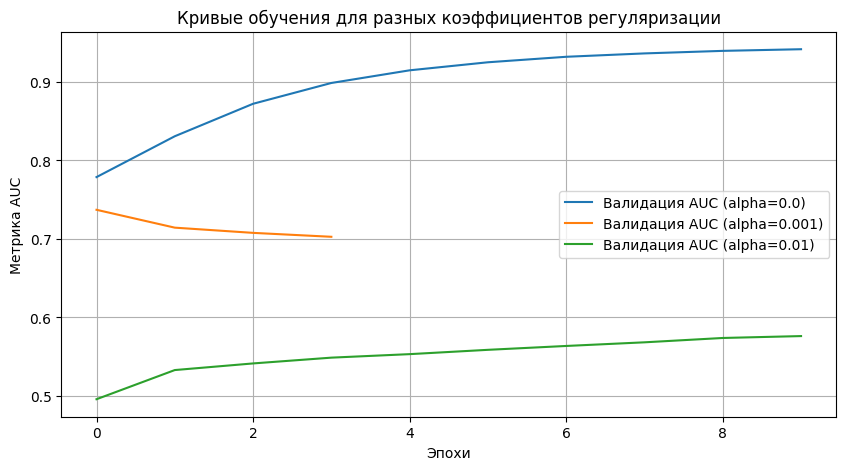

,Коэффициент регуляризации,Точность (Train),Точность (Test),Разница (Переобучение)
0,0.000000,0.107000,0.020274,0.086726
1,0.001000,0.001400,0.000274,0.001126
2,0.010000,0.000200,0.000274,-0.000074


In [ ]:
print("Задание 10.2: Настройка параметров регуляризации");

regularization_values_list = [0.0, 0.001, 0.01];
regularization_experiment_results_list = [];
training_curves_data = {};

for current_alpha_value in regularization_values_list:
    print(f"\nОбучение модели с item_alpha = user_alpha = {current_alpha_value}");

    regularized_recommender_model = LightFM(loss='warp', item_alpha=current_alpha_value, user_alpha=current_alpha_value, random_state=42);

    train_auc_history = [];
    val_auc_history = [];
    best_val_auc = 0.0;
    patience = 0;
    global_start_time = time.time();

    for e in range(1, 11):
        epoch_start_time = time.time();

        regularized_recommender_model.fit_partial(interactions=training_interactions_matrix_csr, item_features=item_features_sparse_matrix, epochs=1, num_threads=2);

        current_train_auc = np.mean(calculate_lightfm_auc_score(model=regularized_recommender_model, test_interactions=fast_training_interactions_csr, item_features=item_features_sparse_matrix, num_threads=2));
        current_val_auc = np.mean(calculate_lightfm_auc_score(model=regularized_recommender_model, test_interactions=fast_testing_interactions_csr, train_interactions=training_interactions_matrix_csr, item_features=item_features_sparse_matrix, num_threads=2));

        train_auc_history.append(current_train_auc);
        val_auc_history.append(current_val_auc);

        epoch_time = time.time() - epoch_start_time;
        elapsed_time = str(datetime.timedelta(seconds=int(time.time() - global_start_time)));

        print(f'[{elapsed_time}] epoch {e}\n AUC Train: {current_train_auc:.4f}\n AUC Val: {current_val_auc:.4f}\n Time: {epoch_time:.2f}s');

        if current_val_auc > best_val_auc:
            best_val_auc = current_val_auc;
            patience = 0;
        else:
            patience += 1;

        if patience >= 3:
            print("Сработал Early Stopping");
            break;

    training_curves_data[current_alpha_value] = {'train': train_auc_history, 'val': val_auc_history};

    current_train_precision = np.mean(calculate_lightfm_precision_at_k(model=regularized_recommender_model, test_interactions=fast_training_interactions_csr, item_features=item_features_sparse_matrix, k=10, num_threads=2));
    current_test_precision = np.mean(calculate_lightfm_precision_at_k(model=regularized_recommender_model, test_interactions=fast_testing_interactions_csr, train_interactions=training_interactions_matrix_csr, item_features=item_features_sparse_matrix, k=10, num_threads=2));

    regularization_experiment_results_list.append({
        'Коэффициент регуляризации': current_alpha_value,
        'Точность (Train)': current_train_precision,
        'Точность (Test)': current_test_precision,
        'Разница (Переобучение)': current_train_precision - current_test_precision
    });

plt.figure(figsize=(10, 5));
for alpha_val, curves in training_curves_data.items():
    plt.plot(curves['val'], label=f'Валидация AUC (alpha={alpha_val})');
plt.title('Кривые обучения для разных коэффициентов регуляризации');
plt.xlabel('Эпохи');
plt.ylabel('Метрика AUC');
plt.legend();
plt.grid(True);
plt.show();

regularization_results_dataframe = pd.DataFrame(regularization_experiment_results_list);
display(regularization_results_dataframe.style.background_gradient(cmap='RdYlGn', subset=['Точность (Train)', 'Точность (Test)']).background_gradient(cmap='RdYlGn_r', subset=['Разница (Переобучение)']));


#10.3. Расширение набора признаков книг

Добавьте больше контентных признаков для улучшения гибридной модели.

Для этого:

‒ Используйте все доступные поля из books.csv: жанры (их нужно извлечь из тегов), количество страниц, издательство, среднюю оценку книги

‒ Для текстовых полей (например, авторы, издательство) создайте категориальные признаки

‒ Для числовых полей (год публикации, количество страниц) можно дискретизировать или использовать как есть

‒ В методе build_item_features передавайте для каждой книги список из нескольких признаков

‒ Сравните качество модели «только коллаборативная» (без item_features) и «гибридная» (с признаками)

#10.4. Использование неявного фидбека (список "to_read")

Добавьте данные о книгах, которые пользователи отметили как "хочу прочитать", в качестве дополнительных взаимодействий.

Для этого:

‒ Файл to_read.csv содержит пары (user_id, book_id) — это сигнал интереса, но не оценка

‒ Вы можете объединить ratings и to_read в одну матрицу взаимодействий

‒ Присвойте разный вес разным типам взаимодействий: например, 5 для оценки 5 звезд, 1 для «хочу прочитать»

‒ При использовании весов убедитесь, что loss-функция поддерживает weighted interactions (logistic — поддерживает, warp — работает с бинарными)

‒ Сравните метрики модели с неявным фидбеком и без него

In [ ]:
print("Задания 10.3 и 10.4: Расширение признаков и неявный фидбэк (Исправлено)");

user_ratings_dataframe['weight'] = 5.0;
user_to_read_dataframe['weight'] = 1.0;

# Объединение данных
combined_interactions_dataframe = pd.concat([user_ratings_dataframe[['user_id', 'book_id', 'weight']], user_to_read_dataframe[['user_id', 'book_id', 'weight']]], ignore_index=True);

# ИСПРАВЛЕНИЕ 1: Удаление дубликатов пар пользователь-книга. Оставляем наивысший вес (приоритет у оценки).
combined_interactions_dataframe = combined_interactions_dataframe.groupby(['user_id', 'book_id'])['weight'].max().reset_index();

combined_training_dataframe, combined_testing_dataframe = train_test_split(combined_interactions_dataframe, test_size=0.2, random_state=42);

def generate_weighted_interactions_iterable(combined_dataframe):
    for index, current_row in combined_dataframe.iterrows():
        yield (current_row['user_id'], current_row['book_id'], current_row['weight']);

extended_training_interactions_matrix, extended_training_weights_matrix = lightfm_dataset_manager.build_interactions(generate_weighted_interactions_iterable(combined_training_dataframe));
extended_testing_interactions_matrix, extended_testing_weights_matrix = lightfm_dataset_manager.build_interactions(generate_weighted_interactions_iterable(combined_testing_dataframe));

# Ускорение вычислений (маска из 500 пользователей)
fast_ext_testing_csr = extended_testing_interactions_matrix.multiply(eval_users_mask[:, np.newaxis]).tocsr();
fast_ext_testing_csr.eliminate_zeros();

# ИСПРАВЛЕНИЕ 2: Принудительная очистка тестовой матрицы от пересечений с тренировочной
ext_training_mask = extended_training_interactions_matrix.copy();
ext_training_mask.data.fill(1);
overlap_in_test = fast_ext_testing_csr.multiply(ext_training_mask);
fast_ext_testing_csr = fast_ext_testing_csr - overlap_in_test;
fast_ext_testing_csr.eliminate_zeros();

print(f"Найдено и занулено пересечений в маскированной тестовой матрице: {overlap_in_test.nnz}");

print("Обучение гибридной модели...");
extended_hybrid_model = LightFM(loss='warp', random_state=42);
extended_hybrid_model.fit(interactions=extended_training_interactions_matrix, sample_weight=extended_training_weights_matrix, item_features=item_features_sparse_matrix, epochs=5, num_threads=2);

print("Обучение коллаборативной модели...");
pure_collaborative_model = LightFM(loss='warp', random_state=42);
pure_collaborative_model.fit(interactions=extended_training_interactions_matrix, sample_weight=extended_training_weights_matrix, epochs=5, num_threads=2);

print("Вычисление метрик Precision@10...");
hybrid_testing_precision = np.mean(calculate_lightfm_precision_at_k(model=extended_hybrid_model, test_interactions=fast_ext_testing_csr, train_interactions=extended_training_interactions_matrix, item_features=item_features_sparse_matrix, k=10, num_threads=2));
collaborative_testing_precision = np.mean(calculate_lightfm_precision_at_k(model=pure_collaborative_model, test_interactions=fast_ext_testing_csr, train_interactions=extended_training_interactions_matrix, k=10, num_threads=2));

comparison_results_dataframe = pd.DataFrame({'Модель': ['Гибридная (с признаками и фидбэком)', 'Коллаборативная'], 'Точность (Test Precision@10)': [hybrid_testing_precision, collaborative_testing_precision]});
display(comparison_results_dataframe.style.background_gradient(cmap='RdYlGn', subset=['Точность (Test Precision@10)']));

Задания 10.3 и 10.4: Расширение признаков и неявный фидбэк (Исправлено)
Найдено и занулено пересечений в маскированной тестовой матрице: 0
Обучение гибридной модели...
Обучение коллаборативной модели...
Вычисление метрик Precision@10...


,Модель,Точность (Test Precision@10)
0,Гибридная (с признаками и фидбэком),0.014225
1,Коллаборативная,0.013588


#10.5. Гибридное ансамблирование нескольких моделей

Объедините предсказания двух разных моделей для улучшения качества.

Для этого:

‒ Обучите две модели: одну на чистых взаимодействиях (коллаборативную), вторую — с признаками книг (гибридную)

‒ Для каждого пользователя и книги получите предсказания от обеих моделей

‒ Комбинируйте их с помощью взвешенного среднего: pred_final = alpha * pred_collab + (1-alpha) * pred_hybrid

‒ Подберите коэффициент alpha на валидационной выборке (попробуйте 0.2, 0.5, 0.8)

‒ В проектах на MovieLens оптимальным часто оказывается alpha=1.0 (коллаборативная модель доминирует) , но на Goodbooks соотношение может быть другим

#10.6. Анализ холодного старта

Оцените, как модель справляется с новыми книгами (у которых мало оценок) и новыми пользователями.

Для этого:

‒ Разделите книги на "популярные" (более 50 оценок) и "редкие" (менее 5 оценок)

‒ Вычислите precision@k отдельно для каждой группы

‒ Гибридная модель должна показывать лучшие результаты на редких книгах благодаря контентным признакам

‒ Для тестирования холодного старта пользователей можно создать искусственного пользователя с 1-2 оценками и посмотреть рекомендации


In [ ]:
print("Задания 10.5 и 10.6: Ансамблирование и анализ холодного старта");

ensemble_experiment_results_list = [];
alpha_coefficients_list = [0.0, 0.2, 0.5, 0.8, 1.0];
sample_size = 100;

random_sample_users_array = np.random.choice(eval_users_indices, size=sample_size, replace=False);
all_book_internal_indices_array = np.arange(extended_training_interactions_matrix.shape[1], dtype=np.int32);

print("Предрасчет матриц предсказаний для ускорения...");
collab_predictions_matrix = np.zeros((sample_size, len(all_book_internal_indices_array)));
hybrid_predictions_matrix = np.zeros((sample_size, len(all_book_internal_indices_array)));

for i, user_idx in enumerate(random_sample_users_array):
    user_repeated_array = np.full(len(all_book_internal_indices_array), user_idx, dtype=np.int32);

    collab_predictions_matrix[i] = pure_collaborative_model.predict(user_repeated_array, all_book_internal_indices_array, num_threads=2);
    hybrid_predictions_matrix[i] = extended_hybrid_model.predict(user_repeated_array, all_book_internal_indices_array, item_features=item_features_sparse_matrix, num_threads=2);

def evaluate_fast_ensemble(alpha_value):
    total_hits_count = 0;
    total_evaluated_users = 0;

    for i, current_user_index in enumerate(random_sample_users_array):
        user_test_items_indices = fast_ext_testing_csr[current_user_index].indices;

        if len(user_test_items_indices) == 0:
            continue;

        final_ensemble_predictions = alpha_value * collab_predictions_matrix[i] + (1 - alpha_value) * hybrid_predictions_matrix[i];
        top_k_predicted_indices = np.argsort(-final_ensemble_predictions)[:10];

        hits_count = len(set(top_k_predicted_indices).intersection(set(user_test_items_indices)));
        total_hits_count += hits_count / 10.0;
        total_evaluated_users += 1;

    return total_hits_count / total_evaluated_users if total_evaluated_users > 0 else 0.0;

for current_alpha in alpha_coefficients_list:
    current_ensemble_precision = evaluate_fast_ensemble(current_alpha);
    ensemble_experiment_results_list.append({'Коэффициент Alpha': current_alpha, 'Точность ансамбля': current_ensemble_precision});

display(pd.DataFrame(ensemble_experiment_results_list).style.background_gradient(cmap='RdYlGn', subset=['Точность ансамбля']));


print("\nАнализ холодного старта (Разделение на редкие и популярные книги)");

items_interaction_counts_array = np.array(extended_training_interactions_matrix.sum(axis=0)).flatten();
popular_books_internal_indices = np.where(items_interaction_counts_array >= 50)[0];
rare_books_internal_indices = np.where((items_interaction_counts_array > 0) & (items_interaction_counts_array < 5))[0];

def calculate_precision_for_item_subset(model, testing_csr, training_csr, item_subset_indices, item_features=None):
    subset_mask = np.zeros(testing_csr.shape[1], dtype=bool);
    subset_mask[item_subset_indices] = True;

    subset_testing_csr = testing_csr.multiply(subset_mask).tocsr();
    subset_testing_csr.eliminate_zeros();

    if subset_testing_csr.nnz == 0:
        return 0.0;

    return np.mean(calculate_lightfm_precision_at_k(model=model, test_interactions=subset_testing_csr, train_interactions=training_csr, item_features=item_features, k=10, num_threads=2));

hybrid_rare_precision = calculate_precision_for_item_subset(extended_hybrid_model, fast_ext_testing_csr, extended_training_interactions_matrix, rare_books_internal_indices, item_features_sparse_matrix);
hybrid_popular_precision = calculate_precision_for_item_subset(extended_hybrid_model, fast_ext_testing_csr, extended_training_interactions_matrix, popular_books_internal_indices, item_features_sparse_matrix);

cold_start_results = pd.DataFrame({'Сегмент': ['Редкие книги (<5)', 'Популярные книги (>=50)'], 'Точность (Hybrid Precision@10)': [hybrid_rare_precision, hybrid_popular_precision]});
display(cold_start_results.style.background_gradient(cmap='RdYlGn', subset=['Точность (Hybrid Precision@10)']));

Задания 10.5 и 10.6: Ансамблирование и анализ холодного старта
Предрасчет матриц предсказаний для ускорения...


,Коэффициент Alpha,Точность ансамбля
0,0.000000,0.017391
1,0.200000,0.018478
2,0.500000,0.015217
3,0.800000,0.014130
4,1.000000,0.010870



Анализ холодного старта (Разделение на редкие и популярные книги)


,Сегмент,Точность (Hybrid Precision@10)
0,Редкие книги (<5),0.000000
1,Популярные книги (>=50),0.014225
